# What hidden processes could explain four omics tables?

Two institutes investigate the same fictional universal disease on **Asteron** and **Borealis**. Each measures RNA and protein from healthy and diseased inhabitants. We will follow their analysis together, starting with how their measurements were generated.

In this first notebook **we are not fitting a model**. We are looking behind the observations to understand the experiment that every later model will try to describe. Planets are sample **groups**; RNA and protein are measurement **views**.

**Before we begin:** if metabolism varies more strongly than inflammation, which process should dominate a method that seeks variance? Could a real biological process be impossible to detect in RNA alone?

### Open the saved experiment

The path setup lets Python find the local [course_utils.py](course_utils.py) file. `from course_utils import *` brings in its helpers, the simulation specification `SPEC`, and names such as `np`, `pd` and `plt`. Importing the module also sets the plotting style; it does not generate data or fit models.

`load_experiment()` reads the four saved `.h5ad` files in `data/observed/`. We load all four for a consistent starting point, but later select explicitly which table each model sees. The teacher arrays remain separate.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

## Meet the inhabitants and their measurements

The next cell checks the design we will carry through all six practicals: 80 Asteron inhabitants, including 40 diseased, and 72 different Borealis inhabitants, including 48 diseased. Each has 90 RNA features and 60 protein features.

`SPEC` is the simulation specification imported from `course_utils`: it holds the seed, sample counts, feature counts, disease counts and noise levels. It is a description of the experiment, not an estimated result. `data` is organised as `data[planet][view]`; each entry is an AnnData object. Its `.X` holds the sample × feature measurements, `.obs` holds inhabitant annotations and `.var` holds feature identifiers.

Read the printed shapes as **inhabitants × features**. The assertion checks that RNA and protein rows refer to the same inhabitants in the same order within each planet. Across planets the inhabitants differ; feature identifiers match within a modality. Values are approximately Gaussian transformed abundances, not counts, so no single-cell QC or count transformation is being performed.

In [3]:
display(pd.DataFrame(SPEC))
for g, views in data.items():
    display(pd.crosstab(views['RNA'].obs.planet, views['RNA'].obs.disease))
    print(g, {v: a.shape for v, a in views.items()})
    assert views['RNA'].obs_names.equals(views['Protein'].obs_names)
display(data['Asteron']['RNA'].obs.head(), data['Asteron']['RNA'].var.head())

,seed,samples,features,diseased,noise_sd,n_processes
Asteron,2026,80.0,NaN,40.0,NaN,6
Borealis,2026,72.0,NaN,48.0,NaN,6
RNA,2026,NaN,90.0,NaN,0.55,6
Protein,2026,NaN,60.0,NaN,1.10,6


disease,Diseased,Healthy
planet,,
Asteron,40,40


Asteron {'RNA': (80, 90), 'Protein': (80, 60)}


disease,Diseased,Healthy
planet,,
Borealis,48,24


Borealis {'RNA': (72, 90), 'Protein': (72, 60)}


,planet,disease,batch
Asteron_000,Asteron,Healthy,0
Asteron_001,Asteron,Healthy,0
Asteron_002,Asteron,Diseased,1
Asteron_003,Asteron,Healthy,0
Asteron_004,Asteron,Diseased,0


""
RNA:feature_000
RNA:feature_001
RNA:feature_002
RNA:feature_003
RNA:feature_004


## Generate scores and weights before observations
Our frozen generator is `simulate()` in [course_utils.py](course_utils.py). It starts a random generator with `SPEC['seed']`, creates sparse or diffuse feature-weight patterns for the six processes, then draws each planet's sample activities with the disease and variability effects below. For each planet–view table it multiplies scores by weights, adds that table's intercept and draws Gaussian observation noise. It returns two structures: observed AnnData tables and a separate teacher dictionary with the generating arrays.

`save_canonical()` used this generator to save the experiment we have just loaded. We are reading those fixed outputs here rather than calling the generator anew. This lets us inspect exactly how our measurements arose while keeping the same data for every later fit.

 $$Y^{(m,g)}_{N_g\times D_m}=\mathbf1\mu^{(m,g)\top}+Z^{(g)}_{N_g\times6}W^{(m)}_{6\times D_m}+E^{(m,g)}_{N_g\times D_m}.$$

 Each score row describes one inhabitant. Each weight row describes one feature pattern. Intercepts capture additive planet offsets; noise is independent Gaussian (RNA SD 0.55; protein SD 1.1). Technical variation is an explicit sixth column of Z with shared, diffuse weights; no hidden planet-specific loading term is added.

 | Process | Activity / feature pattern |
 |---|---|
 | Inflammation | Disease shifts the mean by 1.6; residual score SD .55; both views |
 | Metabolism | Score SD 2, generated independently of disease; both views |
 | RNA program | Nonzero weights only in RNA |
 | Protein program | Nonzero weights only in protein |
 | Planet response | Score SD .15 on Asteron vs 1.6 on Borealis; same weights |
 | Technical | Random laboratory batch plus jitter; diffuse weights, stronger in RNA |

 Borealis also has a **separate +1.8 intercept in the first 10 features** of both views. Greater activity dispersion, different disease composition, and a between-planet mean offset are distinct effects. Finite-sample correlations can occur between independently generated processes.

### Read the matrix picture

`schematic('multigroup')` draws a dimension-labelled diagram from the known sample and feature counts. It performs no calculation on the measurements. Read each row as an observed table approximated by sample activities times feature weights. Repeated score labels connect the two views within a planet; repeated weight labels connect the planets within a view. This is the shared-loading structure used by our generator, before adding intercepts and noise.

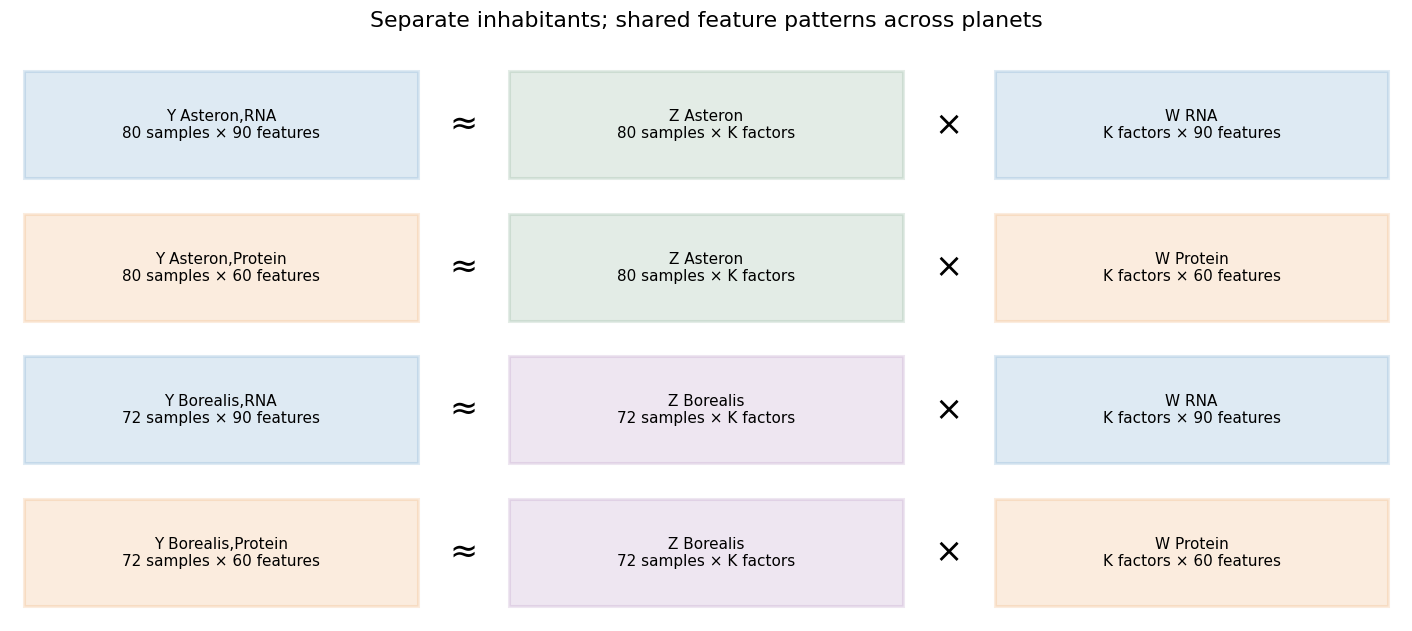

In [4]:
schematic('multigroup')

## Reveal the generating activities, separately from the observations

We have described the generator; now we will inspect its saved answer. **No fitting has taken place.** `load_truth()` reads `data/teacher/truth.npz` and returns a dictionary containing the true sample scores, modality-specific weights, contributions, intercepts and noise. It does not add these arrays to the observed AnnData objects.

`generation_figures(data, teacher)` makes two kinds of plots. First it groups the true activities by disease status within each planet and displays means with **within-status standard deviations**, not uncertainty intervals on the means. It then displays the true feature weights for each modality, showing every third feature to keep the figure readable. Both sets of panels describe what we simulated, not what an algorithm discovered.

**Predict:** will the planet-response activity have a larger mean on Borealis, or mainly a larger spread? Which activities should differ by disease?

,Inflammation,Metabolism,RNA program,Protein program,Planet response,Technical
Asteron_000,-2.066674,2.040019,-1.077680,1.375289,0.254122,-2.069596
Asteron_001,-0.302736,3.715597,-1.102124,0.253852,0.035860,-1.492957
Asteron_002,1.906497,-1.161387,-0.731246,0.267714,0.154668,1.621878
Asteron_003,-1.129762,1.008218,-1.425614,-0.772586,-0.125735,-1.571281
Asteron_004,0.721753,3.688417,0.907361,0.022398,-0.033705,-1.584759


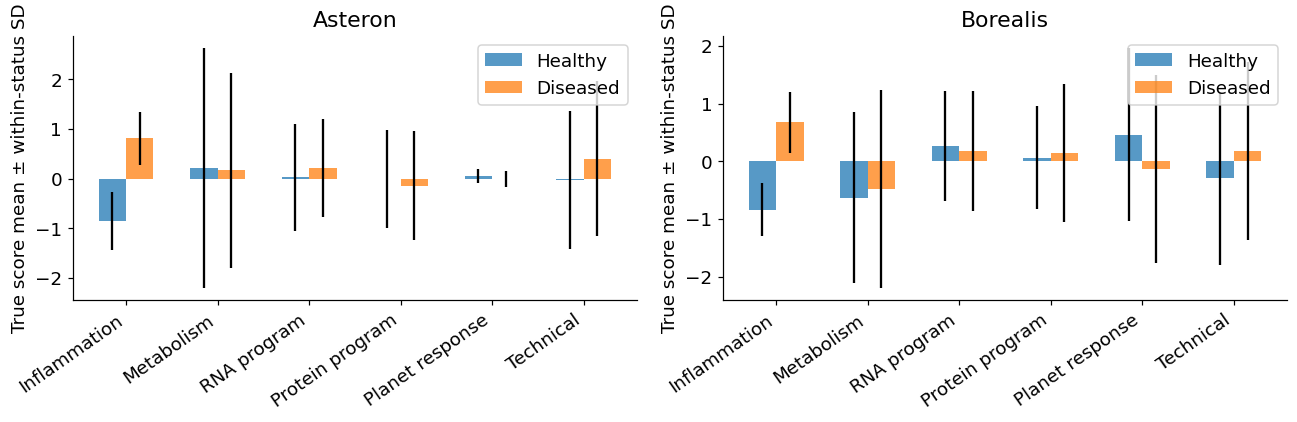

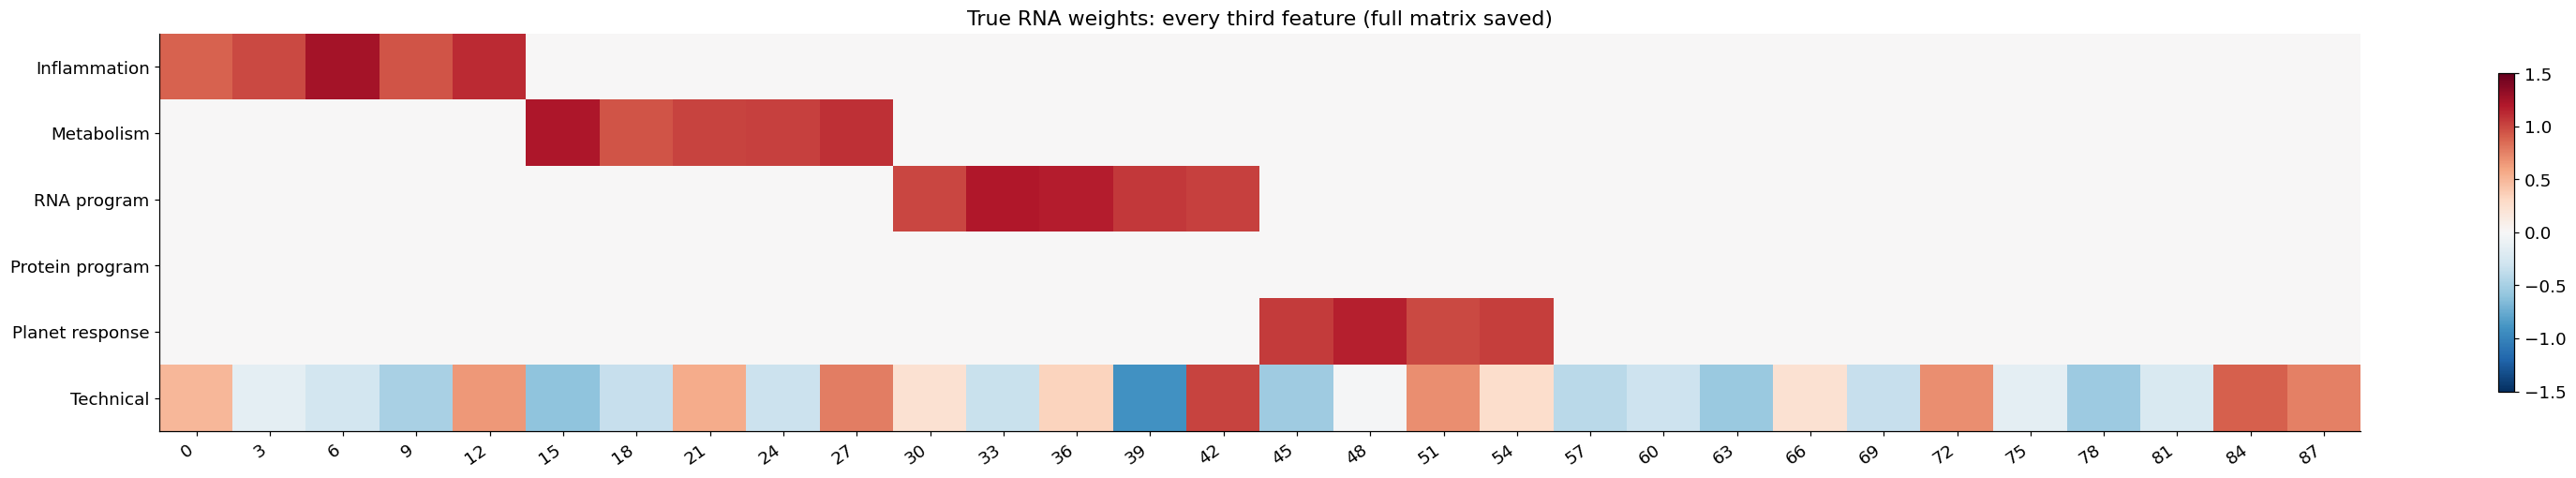

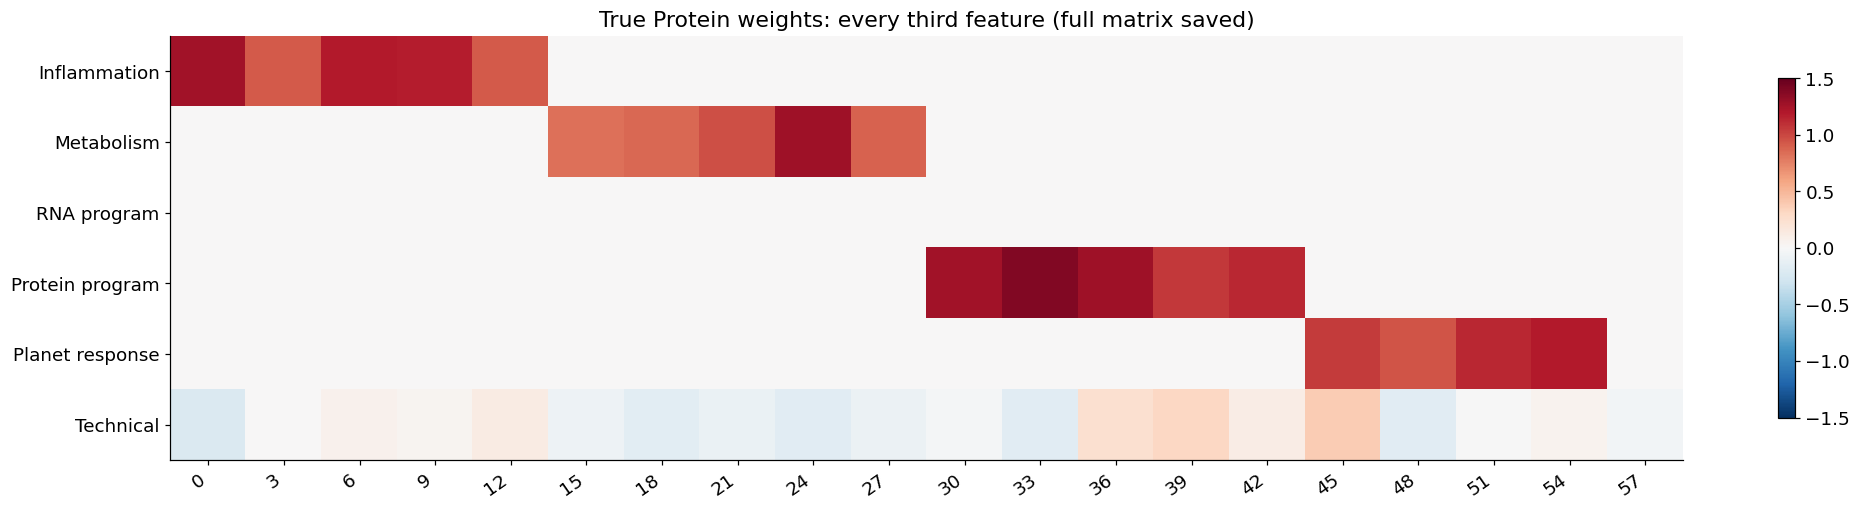

In [5]:
teacher = load_truth()
display(teacher['scores']['Asteron'].head())
generation_figures(data, teacher)

## Build one observed table from its hidden contributions

We now focus on **Asteron's 80 × 90 RNA table**, still without fitting anything. The next cell makes the generator's arithmetic visible. `z` contains 80 × 6 true scores and `w` contains 6 × 90 true weights. The extra axes in `z[:, :, None] * w[None, :, :]` produce an 80 × 6 × 90 array: one contribution for each inhabitant, process and feature. Summing over the six processes gives the signal table. We then add the intercept and the saved measurement noise.

The assertion checks that this calculation reproduces the saved observations. `reconstruction_plot(observed, prediction, title)` only draws three panels: the observed table, the supplied prediction and their difference. It does not estimate a reconstruction. Here we supply the **true signal** as the prediction; later we will supply fitted predictions. Its colour scale is shared across the three panels and set from the observed values. The helper's generic colour-bar label says centred/scaled abundance, but **this particular call uses the original simulated units**. Asteron's intercept is zero, so this residual is the saved noise.

**Predict:** after removing noise and the intercept, should the table equal the product of the true scores and weights?

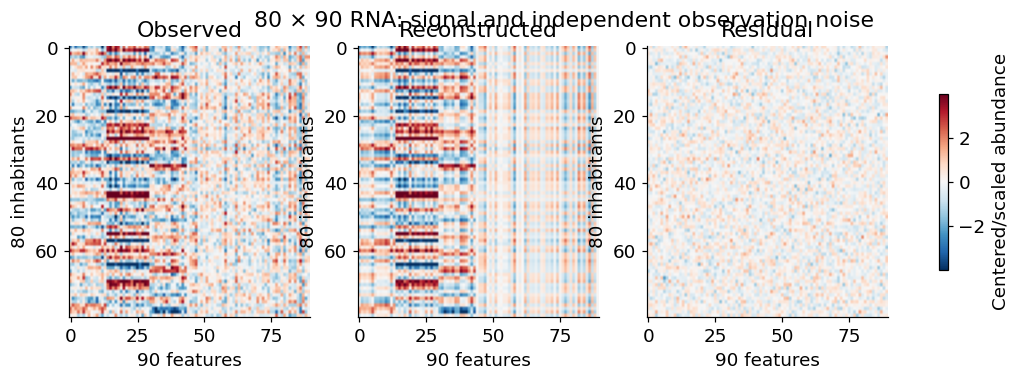

In [6]:
g, v = 'Asteron', 'RNA'
z = teacher['scores'][g].to_numpy()
w = teacher['weights'][v]
parts = z[:, :, None] * w[None, :, :]
signal = parts.sum(axis=1)
y = teacher['intercepts'][g][v] + signal + teacher['noise'][g][v]
assert np.allclose(y, data[g][v].X)
reconstruction_plot(y, signal, '80 × 90 RNA: signal and independent observation noise')

### Return to the measurements the institutes receive

We now draw all four observed tables directly from `.X`, using the same colour limits. Rows are inhabitants and columns are features. These panels contain the combined biological effects, technical variation, intercepts and noise. They are not factor scores or reconstructions. Can you identify a process just by looking at a heatmap, or do we need a model to separate overlapping patterns?

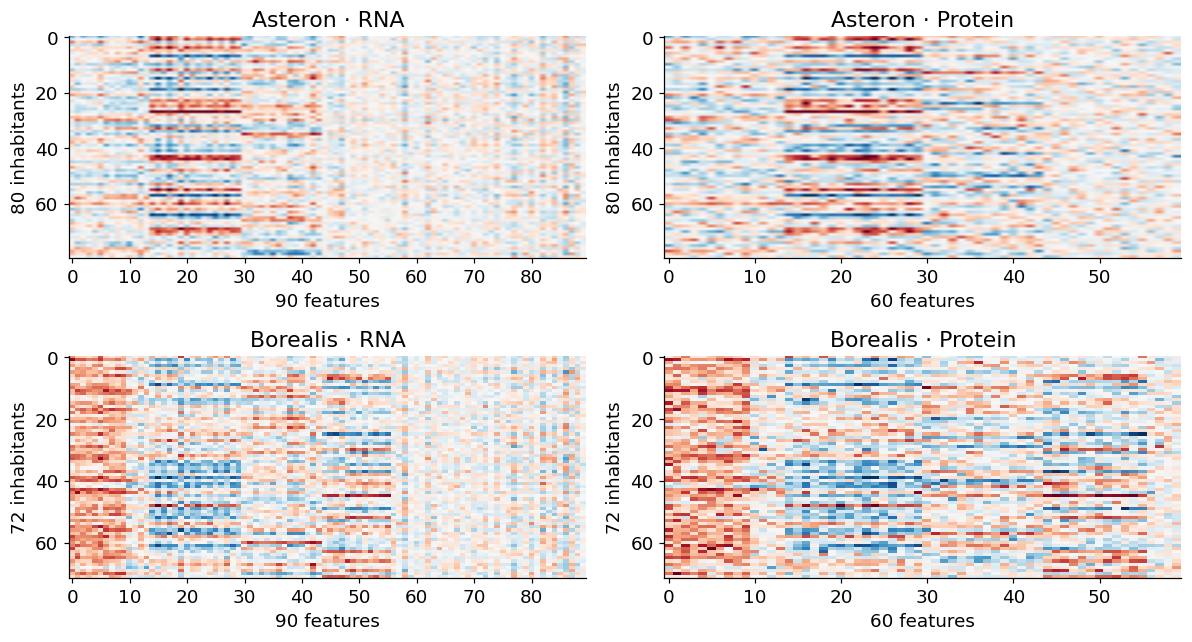

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, g in enumerate(SPEC['samples']):
    for col, v in enumerate(SPEC['features']):
        a = data[g][v]
        axes[row, col].imshow(a.X, aspect='auto', cmap='RdBu_r', vmin=-6, vmax=6)
        axes[row, col].set(title=f'{g} · {v}', xlabel=f'{a.n_vars} features',
                           ylabel=f'{a.n_obs} inhabitants')
fig.tight_layout(); plt.show()

## What do we know before fitting?

The final heatmaps are the four observed tables available to the institutes. We know their full explanation only because we generated them. In later notebooks, fitting uses those observations; true activities and weights are revealed separately for diagnosis.

What do you expect PCA on Asteron RNA to recover first? Why might a strong axis describe metabolism rather than disease? Which simulated effects might remain difficult to recover: the protein-only program with zero RNA weights, weak planet-response activity on Asteron, or a technical effect spread across many features?

We have connected activities and feature patterns to measured tables. We have not established that an estimated axis will recover one generating process. **Next we hide the teacher arrays and fit PCA to Asteron RNA alone.**

For optional exploration, open [course_utils.py](course_utils.py) at `simulate()` and trace the construction of scores, weights and noise. `save_canonical()` regenerates the saved experiment with the fixed specification; it is not called by the modelling notebooks. Keep the same experiment throughout the course.

Sources: [MOFA](https://doi.org/10.15252/msb.20178124), [MOFA+](https://doi.org/10.1186/s13059-020-02015-1), [MOFA-FLEX preprint](https://doi.org/10.1101/2025.11.03.686250). API and validation notes: [AUDIT](../AUDIT.md).